# Chapitre 11 - Lab : capture des changements avec le décodage logique de PostgreSQL

Le cours 3 a implémenté une CDC jouet par déclencheurs sur SQLite. Les outils réels
(Debezium et consorts) lisent plutôt le **journal d'écriture anticipée** (WAL) de la base,
décodé en changements logiques. Ce lab utilise directement ce mécanisme dans
PostgreSQL 16 : un **slot de réplication logique** avec le module de sortie
`test_decoding`, interrogé en SQL (`pg_logical_slot_get_changes`). On y retrouve, sur un
vrai système, les notions du cours : ordre de validation, position dans le journal (LSN),
système dérivé qui suit la base, instantané initial cohérent, et retard d'un consommateur.

**Démarrer et arrêter les services** (depuis la racine du dépôt) :

```bash
docker compose -f docker/streams/compose.yml -p ddia_streams up -d --wait
# ... exécuter le notebook ...
docker compose -f docker/streams/compose.yml -p ddia_streams down -v
```

PostgreSQL écoute sur le port **11232** de l'hôte (utilisateur et mot de passe `ddia`, base
`flux`), avec `wal_level=logical`.

**Plan.**

1. Un slot de réplication logique : le journal des changements en SQL.
2. L'ordre du journal est l'ordre de validation.
3. Ce que contient un changement : `REPLICA IDENTITY`.
4. Un index dérivé qui suit la base, face à la double écriture.
5. L'instantané initial cohérent.
6. Un slot retient le WAL : le retard du consommateur a un coût.

In [1]:
import re
import threading
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg

from ddia import streams as st
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.max_colwidth", 200)
DSN = "host=localhost port=11232 user=ddia password=ddia dbname=flux connect_timeout=5"

def sql(requete, params=None):
    with psycopg.connect(DSN, autocommit=True) as c:
        cur = c.execute(requete, params)
        return cur.fetchall() if cur.description else None

print(sql("SELECT version()")[0][0].split(",")[0], "; wal_level =", sql("SHOW wal_level")[0][0])
for (slot,) in sql("SELECT slot_name FROM pg_replication_slots"):
    sql("SELECT pg_drop_replication_slot(%s)", (slot,))            # notebook relançable
sql("DROP TABLE IF EXISTS produits")
sql("CREATE TABLE produits (id INTEGER PRIMARY KEY, nom TEXT, description TEXT, prix NUMERIC)")

PostgreSQL 16.14 (Debian 16.14-1.pgdg13+1) on x86_64-pc-linux-gnu ; wal_level = logical


## 1. Un slot de réplication logique (sections *Change Data Capture* et *Implementing change data capture*)

Un **slot** mémorise la position d'un consommateur dans le WAL, comme l'offset validé
d'un groupe Kafka. `pg_logical_slot_peek_changes` lit les changements sans avancer la
position ; `pg_logical_slot_get_changes` les lit **et** avance la position (on « valide »).
Chaque changement porte son **LSN** (log sequence number), sa position dans le WAL, et
l'identifiant de la transaction (`xid`).

In [2]:
sql("SELECT pg_create_logical_replication_slot('cdc_demo', 'test_decoding')")
sql("INSERT INTO produits VALUES (1, 'Lampe', 'lampe de bureau en laiton', 49)")
sql("INSERT INTO produits VALUES (2, 'Chaise', 'chaise en chêne massif', 120)")
sql("UPDATE produits SET prix = 45 WHERE id = 1")
sql("DELETE FROM produits WHERE id = 2")
apercu = sql("SELECT lsn::text, xid::text, data FROM pg_logical_slot_peek_changes('cdc_demo', NULL, NULL)")
print(f"{len(apercu)} lignes lues sans avancer ; relues : {len(sql('SELECT * FROM pg_logical_slot_peek_changes(%s, NULL, NULL)', ('cdc_demo',)))}")
pd.DataFrame(apercu, columns=["lsn", "xid", "changement (test_decoding)"])

12 lignes lues sans avancer ; relues : 12


,lsn,xid,changement (test_decoding)
0,0/1B964F0,4963,BEGIN 4963
1,0/1B964F0,4963,table public.produits: INSERT: id[integer]:1 nom[text]:'Lampe' description[text]:'lampe de bureau en laiton' prix[numeric]:49
2,0/1B96620,4963,COMMIT 4963
3,0/1B96620,4964,BEGIN 4964
4,0/1B96620,4964,table public.produits: INSERT: id[integer]:2 nom[text]:'Chaise' description[text]:'chaise en chêne massif' prix[numeric]:120
5,0/1B966F0,4964,COMMIT 4964
6,0/1B966F0,4965,BEGIN 4965
7,0/1B966F0,4965,table public.produits: UPDATE: id[integer]:1 nom[text]:'Lampe' description[text]:'lampe de bureau en laiton' prix[numeric]:45
8,0/1B96790,4965,COMMIT 4965
9,0/1B96790,4966,BEGIN 4966


Chaque instruction exécutée en mode autocommit est une transaction : le journal montre
des blocs `BEGIN ... COMMIT`, et dedans un changement par ligne touchée, au format texte
de `test_decoding` (les outils de production utilisent `pgoutput`, binaire, mais
l'information est la même). Écrivons un petit analyseur, puis consommons pour de bon.

In [3]:
MOTIF = re.compile(r"table public\.(\w+): (INSERT|UPDATE|DELETE): (.*)")
CHAMP = re.compile(r"(\w+)\[[^\]]+\]:('(?:[^']|'')*'|\S+)")

def analyser(data):
    """Ligne test_decoding -> dict (table, op, ligne), ou None pour BEGIN/COMMIT."""
    m = MOTIF.match(data)
    if not m:
        return None
    table, op, reste = m.groups()
    champs = {k: (v[1:-1].replace("''", "'") if v.startswith("'") else (None if v == "null" else v))
              for k, v in CHAMP.findall(reste)}
    return {"table": table, "op": op.lower(), "ligne": champs}

def consommer(slot="cdc_demo", limite=None):
    rows = sql("SELECT lsn::text, xid::text, data FROM pg_logical_slot_get_changes(%s, NULL, %s)", (slot, limite))
    return [dict(lsn=l, xid=int(x), brut=d, **c) for l, x, d in rows if (c := analyser(d))]

pd.DataFrame(consommer()).drop(columns="brut")

,lsn,xid,table,op,ligne
0,0/1B964F0,4963,produits,insert,"{'id': '1', 'nom': 'Lampe', 'description': 'lampe de bureau en laiton', 'prix': '49'}"
1,0/1B96620,4964,produits,insert,"{'id': '2', 'nom': 'Chaise', 'description': 'chaise en chêne massif', 'prix': '120'}"
2,0/1B966F0,4965,produits,update,"{'id': '1', 'nom': 'Lampe', 'description': 'lampe de bureau en laiton', 'prix': '45'}"
3,0/1B96790,4966,produits,delete,{'id': '2'}


Après `get_changes`, le slot a avancé : une nouvelle lecture ne renvoie plus rien tant
qu'il n'y a pas de nouvelles écritures.

> **À retenir.** Un slot de réplication logique expose le WAL comme un flux de
> changements ligne à ligne, chacun avec sa position (LSN) ; le slot mémorise la position
> du consommateur.

In [4]:
print("relecture après consommation :", consommer())

relecture après consommation : []


## 2. L'ordre du journal est l'ordre de validation (section *Keeping Systems in Sync*)

Deux transactions concurrentes : T1 commence d'abord et modifie le produit 1, T2 commence
ensuite, modifie le produit 3 et **valide la première**. Dans quel ordre le journal les
présente-t-il ?

In [5]:
sql("INSERT INTO produits VALUES (3, 'Table', 'table basse en noyer', 210)")
consommer()                                                    # on repart d'un journal vide
t1, t2 = psycopg.connect(DSN), psycopg.connect(DSN)
chrono = []
t1.execute("UPDATE produits SET prix = 40 WHERE id = 1"); chrono.append(("T1", "écrit produit 1"))
t2.execute("UPDATE produits SET prix = 199 WHERE id = 3"); chrono.append(("T2", "écrit produit 3"))
t2.commit(); chrono.append(("T2", "COMMIT"))
t1.commit(); chrono.append(("T1", "COMMIT"))
t1.close(); t2.close()
journal = consommer()
print("chronologie des instructions :", chrono)
pd.DataFrame(journal)[["lsn", "xid", "op", "ligne"]]

chronologie des instructions : [('T1', 'écrit produit 1'), ('T2', 'écrit produit 3'), ('T2', 'COMMIT'), ('T1', 'COMMIT')]


,lsn,xid,op,ligne
0,0/1B96940,4969,update,"{'id': '3', 'nom': 'Table', 'description': 'table basse en noyer', 'prix': '199'}"
1,0/1B968D0,4968,update,"{'id': '1', 'nom': 'Lampe', 'description': 'lampe de bureau en laiton', 'prix': '40'}"


T1 a écrit en premier, mais le journal présente T2 d'abord : les changements d'une
transaction n'y apparaissent qu'à sa **validation**, dans l'**ordre des validations**.
C'est exactement ce qu'il faut pour un système dérivé : la base a tranché l'ordre, et
tout consommateur qui applique le journal dans l'ordre obtient le même état qu'elle (une
transaction annulée, elle, n'apparaît pas du tout).

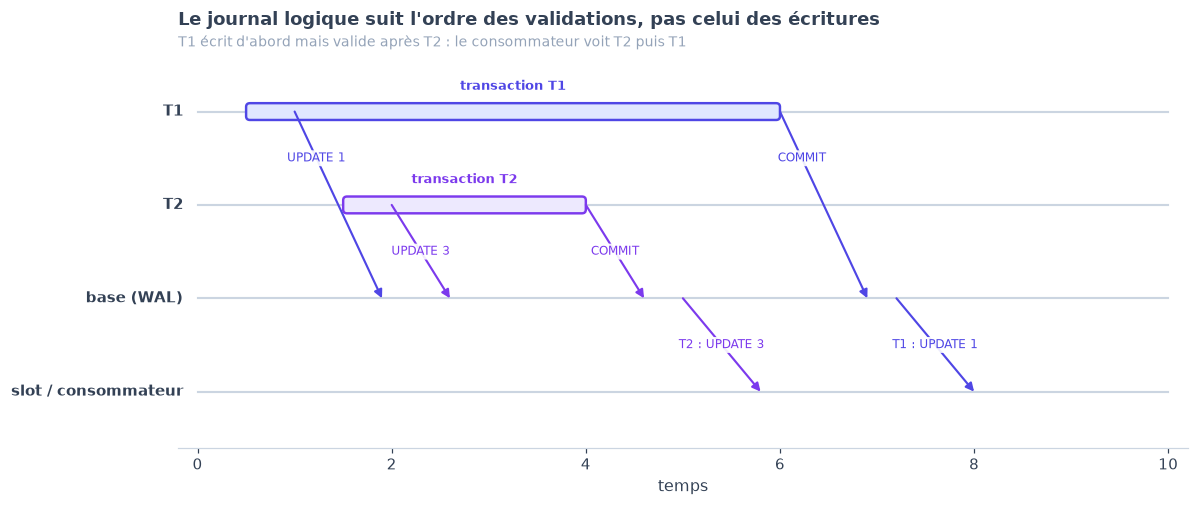

In [6]:
stt = SpaceTime(["T1", "T2", "base (WAL)", "slot / consommateur"], t_max=10, width=11,
                title="Le journal logique suit l'ordre des validations, pas celui des écritures",
                subtitle="T1 écrit d'abord mais valide après T2 : le consommateur voit T2 puis T1")
stt.op("T1", 0.5, 6.0, "transaction T1", color=INDIGO)
stt.op("T2", 1.5, 4.0, "transaction T2", color=VIOLET)
stt.msg("T1", 1.0, "base (WAL)", 1.9, "UPDATE 1", color=INDIGO, label_pos=0.25)
stt.msg("T2", 2.0, "base (WAL)", 2.6, "UPDATE 3", color=VIOLET)
stt.msg("T2", 4.0, "base (WAL)", 4.6, "COMMIT", color=VIOLET)
stt.msg("T1", 6.0, "base (WAL)", 6.9, "COMMIT", color=INDIGO, label_pos=0.25)
stt.msg("base (WAL)", 5.0, "slot / consommateur", 5.8, "T2 : UPDATE 3", color=VIOLET)
stt.msg("base (WAL)", 7.2, "slot / consommateur", 8.0, "T1 : UPDATE 1", color=INDIGO)
stt.show()

> **À retenir.** Le décodage logique livre les transactions entières, dans l'ordre de leur
> validation : c'est l'ordre « décidé par le leader » dont la CDC a besoin.

## 3. Ce que contient un changement : `REPLICA IDENTITY` (section *Log compaction*)

Pour être compactable et applicable sans relire la base, un événement de CDC doit
contenir la clé et la **valeur complète** de la ligne. Que publie PostgreSQL ?

In [7]:
sql("UPDATE produits SET prix = 42 WHERE id = 1")
sql("DELETE FROM produits WHERE id = 3")
defaut = consommer()
sql("ALTER TABLE produits REPLICA IDENTITY FULL")
sql("UPDATE produits SET prix = 41 WHERE id = 1")
sql("INSERT INTO produits VALUES (4, 'Tapis', 'tapis en laine', 90)")
sql("DELETE FROM produits WHERE id = 4")
complet = consommer()
sql("ALTER TABLE produits REPLICA IDENTITY DEFAULT")
pd.DataFrame([{"identité": "DEFAULT", "op": c["op"], "sortie de test_decoding": c["brut"].split(": ", 2)[2]} for c in defaut] +
             [{"identité": "FULL", "op": c["op"], "sortie de test_decoding": c["brut"].split(": ", 2)[2]} for c in complet])

,identité,op,sortie de test_decoding
0,DEFAULT,update,id[integer]:1 nom[text]:'Lampe' description[text]:'lampe de bureau en laiton' prix[numeric]:42
1,DEFAULT,delete,id[integer]:3
2,FULL,update,old-key: id[integer]:1 nom[text]:'Lampe' description[text]:'lampe de bureau en laiton' prix[numeric]:42 new-tuple: id[integer]:1 nom[text]:'Lampe' description[text]:'lampe de bureau en laiton' pri...
3,FULL,insert,id[integer]:4 nom[text]:'Tapis' description[text]:'tapis en laine' prix[numeric]:90
4,FULL,delete,id[integer]:4 nom[text]:'Tapis' description[text]:'tapis en laine' prix[numeric]:90


Les INSERT et UPDATE publient toujours la **nouvelle ligne complète** : un consommateur peut
donc garder la dernière valeur par clé (compaction). Pour un DELETE, l'identité par défaut
ne publie que la clé primaire (une pierre tombale). Avec `REPLICA IDENTITY FULL`, un
UPDATE publie aussi l'**ancienne** ligne complète (`old-key:` puis `new-tuple:`) et un
DELETE la ligne supprimée entière : utile à un consommateur qui doit retirer l'ancienne
version d'un index ou calculer une différence, au prix d'un WAL plus volumineux.

> **À retenir.** Avec l'identité par défaut, chaque changement porte la clé et la nouvelle
> ligne entière (ou seulement la clé pour une suppression) : le flux est compactable par
> clé.

## 4. Un index dérivé qui suit la base, face à la double écriture (sections *Keeping Systems in Sync* et *Change Data Capture*)

Huit fils mettent à jour en même temps la description de 20 produits. En **double
écriture**, chaque fil écrit dans PostgreSQL puis, après un petit délai aléatoire (le
réseau, une pause), dans un index plein texte en mémoire (`st.SearchIndex`). En **CDC**,
l'index est alimenté uniquement par le slot. On compare ensuite chaque index au contenu
de la base.

In [8]:
sql("TRUNCATE produits")
for i in range(20):
    sql("INSERT INTO produits VALUES (%s, %s, %s, 10)", (i, f"p{i}", f"produit {i} version initiale"))
consommer()
idx_double = st.SearchIndex()
idx_cdc = st.SearchIndex()
for i in range(20):
    idx_double.upsert(str(i), f"produit {i} version initiale")
    idx_cdc.upsert(str(i), f"produit {i} version initiale")
verrou = threading.Lock()

def client(n, graine):
    r = np.random.default_rng(graine)
    with psycopg.connect(DSN, autocommit=True) as c:
        for k in range(60):
            pid = int(r.integers(0, 20))
            texte = f"produit {pid} écrit par client{n} étape{k}"
            c.execute("UPDATE produits SET description = %s WHERE id = %s", (texte, pid))
            time.sleep(float(r.exponential(0.01)))            # délai entre les deux écritures
            with verrou:
                idx_double.upsert(str(pid), texte)

fils = [threading.Thread(target=client, args=(n, n)) for n in range(8)]
for f in fils:
    f.start()
for f in fils:
    f.join()
for ch in consommer():                                         # le consommateur CDC rattrape le journal
    if ch["table"] == "produits" and ch["op"] in ("insert", "update"):
        idx_cdc.upsert(ch["ligne"]["id"], ch["ligne"]["description"])
base = {str(k): v for k, v in sql("SELECT id, description FROM produits")}
ecarts = {nom: sum(ix.docs.get(k) != v for k, v in base.items()) for nom, ix in
          [("double écriture", idx_double), ("CDC (slot logique)", idx_cdc)]}
pd.DataFrame({"produits divergents (sur 20)": ecarts})

,produits divergents (sur 20)
double écriture,3
CDC (slot logique),0


Avec 480 mises à jour concurrentes, la double écriture laisse typiquement plusieurs
produits dont l'index ne reflète pas la base (le chiffre exact varie d'une exécution à
l'autre, puisqu'il dépend de l'ordonnancement réel des fils) ; l'index alimenté par le
slot est toujours identique à la base, puisqu'il applique les changements dans l'ordre où
PostgreSQL les a validés.

> **À retenir.** Sur un vrai système, la double écriture concurrente diverge et la CDC
> converge : seul le leader décide de l'ordre.

## 5. L'instantané initial cohérent (section *Initial snapshot*)

Pour construire un nouvel index, il faut un instantané **et** sa position dans le journal.
Méthode : (1) créer le slot (il capture tout ce qui sera validé après sa création) ;
(2) lire la table dans une transaction `REPEATABLE READ` et noter son instantané MVCC
(`pg_current_snapshot()`, chapitre 7) ; (3) appliquer ensuite les
changements du slot **en ignorant ceux des transactions déjà visibles dans
l'instantané**. Un fil écrit pendant toute l'opération, pour créer des recouvrements.

In [9]:
sql("SELECT pg_create_logical_replication_slot('cdc_snapshot', 'test_decoding')")
arret = threading.Event()

def ecrivain():
    r = np.random.default_rng(42)
    with psycopg.connect(DSN, autocommit=True) as c:
        k = 0
        while not arret.is_set():
            pid = int(r.integers(0, 20))
            c.execute("UPDATE produits SET description = %s WHERE id = %s", (f"produit {pid} rev {k}", pid))
            k += 1
            time.sleep(0.002)

f = threading.Thread(target=ecrivain)
f.start()
time.sleep(0.3)
with psycopg.connect(DSN) as c:
    c.execute("BEGIN ISOLATION LEVEL REPEATABLE READ")
    instantane = c.execute("SELECT pg_current_snapshot()::text").fetchone()[0]
    lignes = c.execute("SELECT id, description FROM produits").fetchall()
    time.sleep(0.3)                                            # l'écrivain continue pendant la lecture
    c.execute("COMMIT")
time.sleep(0.3)
arret.set(); f.join()
xmin, xmax, xip = instantane.split(":")
en_cours = {int(x) for x in xip.split(",") if x}
visible = lambda xid: xid < int(xmin) or (xid < int(xmax) and xid not in en_cours)
changements = consommer("cdc_snapshot")
resultats = {}
for nom, filtrer in [("instantané + tout le slot", False), ("instantané + slot filtré par visibilité", True)]:
    ix = {str(k): v for k, v in lignes}
    for ch in changements:
        if filtrer and visible(ch["xid"]):
            continue                                           # déjà dans l'instantané
        ix[ch["ligne"]["id"]] = ch["ligne"]["description"]
    base = {str(k): v for k, v in sql("SELECT id, description FROM produits")}
    deja = sum(visible(ch["xid"]) for ch in changements)
    resultats[nom] = {"changements appliqués": len(changements) - (deja if filtrer else 0),
                      "changements déjà dans l'instantané": deja,
                      "produits divergents": sum(ix.get(k) != v for k, v in base.items())}
print("instantané MVCC :", instantane)
pd.DataFrame(resultats).T

instantané MVCC : 5609:5609:


,changements appliqués,changements déjà dans l'instantané,produits divergents
instantané + tout le slot,395,131,0
instantané + slot filtré par visibilité,264,131,0


Le slot, créé avant l'instantané, contient aussi des changements que l'instantané voit
déjà. Ici, les réappliquer ne fausse pas le résultat final (ce sont des remplacements de
ligne complète, appliqués dans l'ordre : l'opération est idempotente), mais ce ne serait
pas le cas pour un consommateur qui incrémente un compteur ou envoie une notification par
changement. Le filtre par visibilité MVCC donne la frontière exacte : chaque transaction
est appliquée **une seule fois**, soit par l'instantané, soit par le flux. (Les outils de
CDC font la même chose, par exemple en exportant l'instantané au moment de la création du
slot.)

> **À retenir.** L'instantané initial et le flux doivent se raccorder exactement ;
> l'instantané MVCC fournit la frontière (quelles transactions il contient déjà).

## 6. Un slot retient le WAL (sections *Disk space usage* et *When consumers cannot keep up with producers*)

Contrairement à un journal Kafka à rétention fixe, un slot **empêche** PostgreSQL de
recycler le WAL que son consommateur n'a pas encore lu : le retard du consommateur se
paie en disque, sans limite (sauf à fixer `max_slot_wal_keep_size`). On écrit en continu
sans consommer, puis on consomme, en suivant la quantité de WAL retenue par le slot.

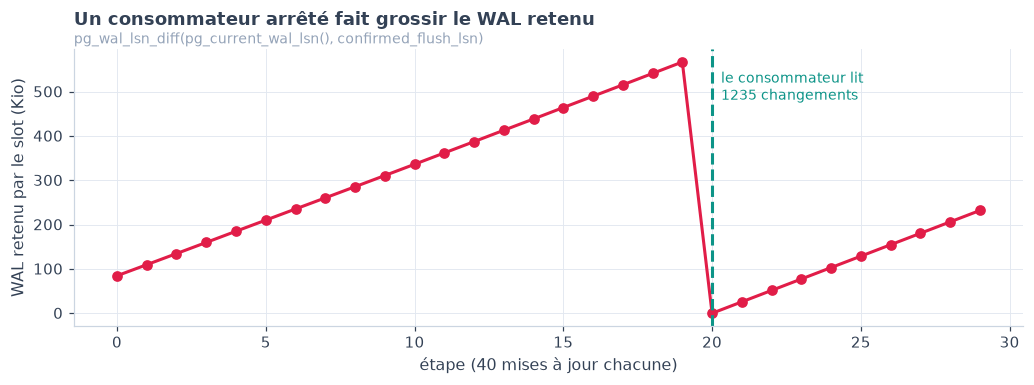

In [10]:
def retenu():
    return sql("SELECT pg_wal_lsn_diff(pg_current_wal_lsn(), confirmed_flush_lsn) FROM pg_replication_slots "
               "WHERE slot_name = 'cdc_demo'")[0][0]

suivi, t0 = [], time.time()
with psycopg.connect(DSN, autocommit=True) as c:
    for etape in range(30):
        for _ in range(40):
            c.execute("UPDATE produits SET description = repeat('x', 500) || %s WHERE id = %s",
                      (str(etape), etape % 20))
        if etape == 20:
            n = len(consommer())                                # le consommateur se réveille
        suivi.append((etape, float(retenu()) / 1024))
S = pd.DataFrame(suivi, columns=["étape", "WAL retenu (Kio)"])
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.plot(S["étape"], S["WAL retenu (Kio)"], "o-", color=ROSE)
ax.axvline(20, color=TEAL, ls="--")
ax.text(20.3, S["WAL retenu (Kio)"].max() * 0.85, f"le consommateur lit\n{n} changements", color=TEAL, fontsize=9)
ax.set_xlabel("étape (40 mises à jour chacune)"); ax.set_ylabel("WAL retenu par le slot (Kio)")
ax.set_title("Un consommateur arrêté fait grossir le WAL retenu")
subtitle(ax, "pg_wal_lsn_diff(pg_current_wal_lsn(), confirmed_flush_lsn)")
plt.tight_layout(); plt.show()

Le WAL retenu croît linéairement tant que personne ne consomme, et retombe dès que le
consommateur avance sa position. Un consommateur de CDC abandonné (slot jamais supprimé)
finit par **remplir le disque** du serveur de base : on surveille donc le retard des slots
comme celui des groupes Kafka, et l'on supprime les slots inutiles.

> **À retenir.** La position d'un slot est l'équivalent d'un offset validé ; mais tant
> qu'elle n'avance pas, PostgreSQL garde le WAL correspondant.

In [11]:
for (slot,) in sql("SELECT slot_name FROM pg_replication_slots"):
    sql("SELECT pg_drop_replication_slot(%s)", (slot,))
sql("DROP TABLE produits")
print("slots supprimés :", sql("SELECT count(*) FROM pg_replication_slots")[0][0] == 0)

slots supprimés : True
